# Local trend dynamics

This notebook illustrates `trend_dynamics` for several synthetic time-series shapes. The diagnostic uses a Savitzky-Golay local polynomial and displays the smoothed trend, local slope, and local acceleration. The examples are synthetic so that the expected signs of the derivatives are known in advance.

In [2]:
import numpy as np
import pandas as pd
import sys
import os
sys.path.append(os.path.abspath("../.."))
from tinyshift.plot import trend_dynamics

## Example series

All series are daily and regularly spaced. A small amount of random noise makes them resemble observed data rather than exact polynomial curves.

In [3]:
n = 121
t = np.arange(n, dtype=float)
dates = pd.date_range("2025-01-01", periods=n, freq="D")
rng = np.random.default_rng(42)
noise = lambda scale: rng.normal(0, scale, n)

examples = {
    "linear": 5 + 0.10 * t + noise(0.20),
    "accelerating": 5 + 0.02 * t + 0.0015 * t**2 + noise(0.25),
    "decelerating": 5 + 0.50 * t - 0.0020 * t**2 + noise(0.25),
    "turning_point": 18 - 0.0035 * (t - 60) ** 2 + noise(0.20),
    "structural_break": np.where(t < 60, 5 + 0.03 * t, 6.8 + 0.18 * (t - 60)) + noise(0.20),
    "seasonal_noisy": 8 + 0.05 * t + 1.5 * np.sin(2 * np.pi * t / 7) + noise(0.35),
}

df = pd.concat(
    [pd.DataFrame({"unique_id": name, "ds": dates, "y": values})
     for name, values in examples.items()],
    ignore_index=True,
)
df.groupby("unique_id", sort=False)["y"].agg(["min", "max", "mean"]).round(2)

,min,max,mean
unique_id,,,
linear,4.89,17.12,10.99
accelerating,4.88,28.98,13.42
decelerating,4.56,36.45,25.38
turning_point,5.19,18.29,13.73
structural_break,4.90,17.49,9.05
seasonal_noisy,6.43,15.68,10.96


## Linear trend

A linear trend should produce an approximately constant positive slope and acceleration close to zero.

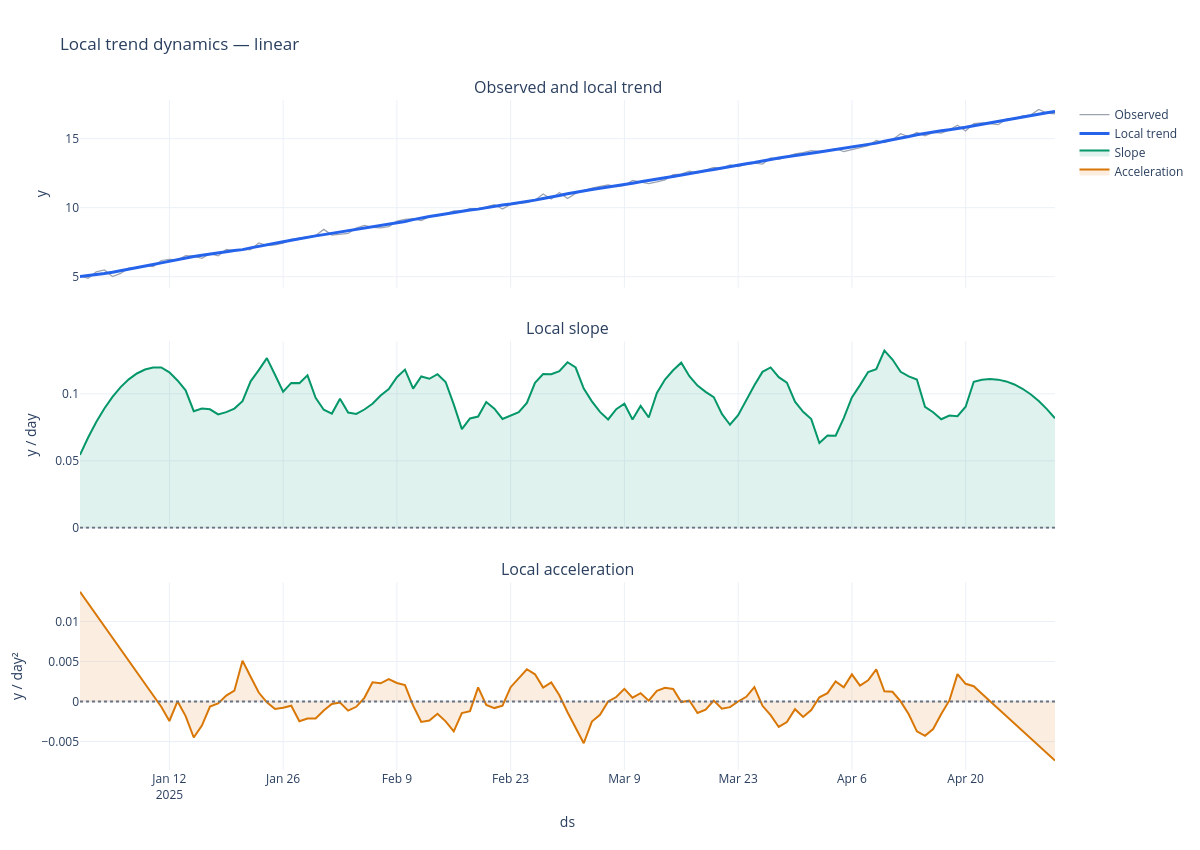

In [4]:
trend_dynamics(
    df, unique_id="linear", window_length=21,
    time_unit="day", fig_type="png",
)

## Acceleration and deceleration

The accelerating series has an increasing slope and positive acceleration. The decelerating series continues growing, but its slope declines and its acceleration is negative.

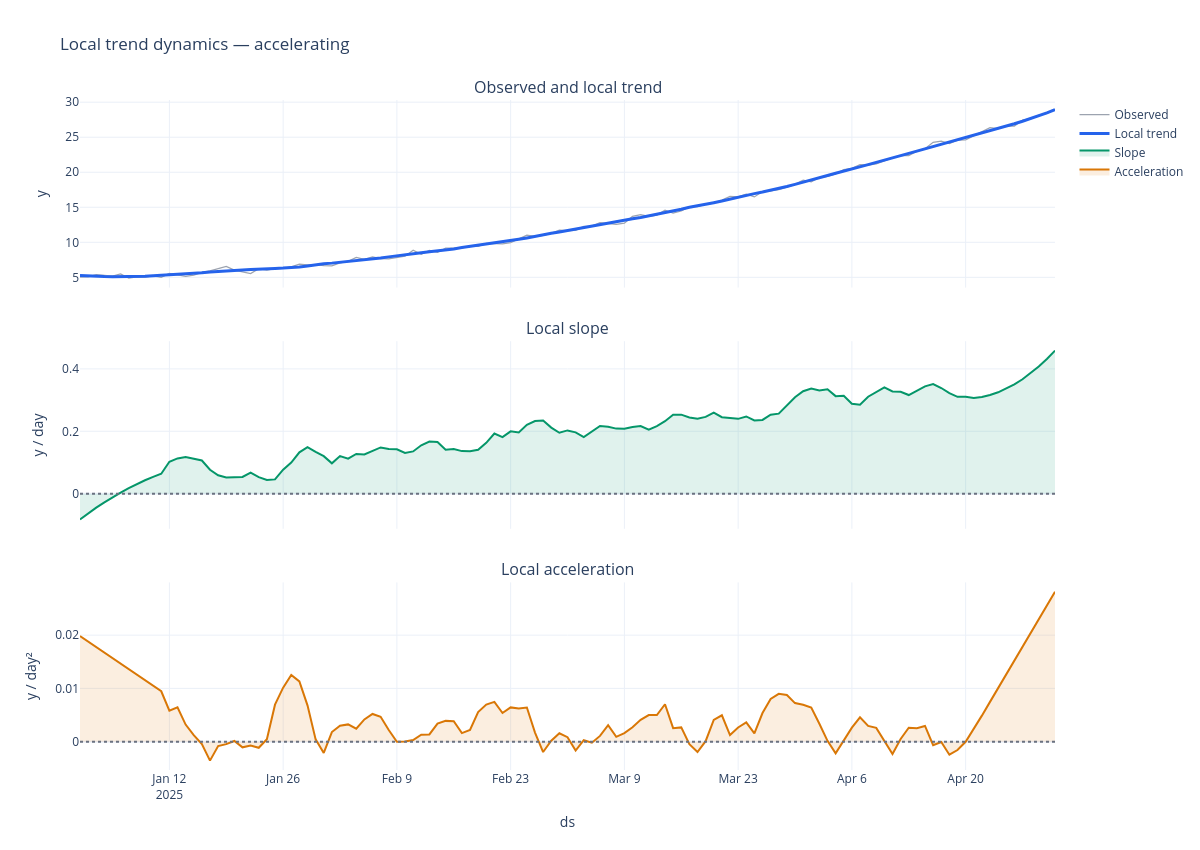

In [5]:
trend_dynamics(
    df, unique_id="accelerating", window_length=21,
    time_unit="day", fig_type="png",
)

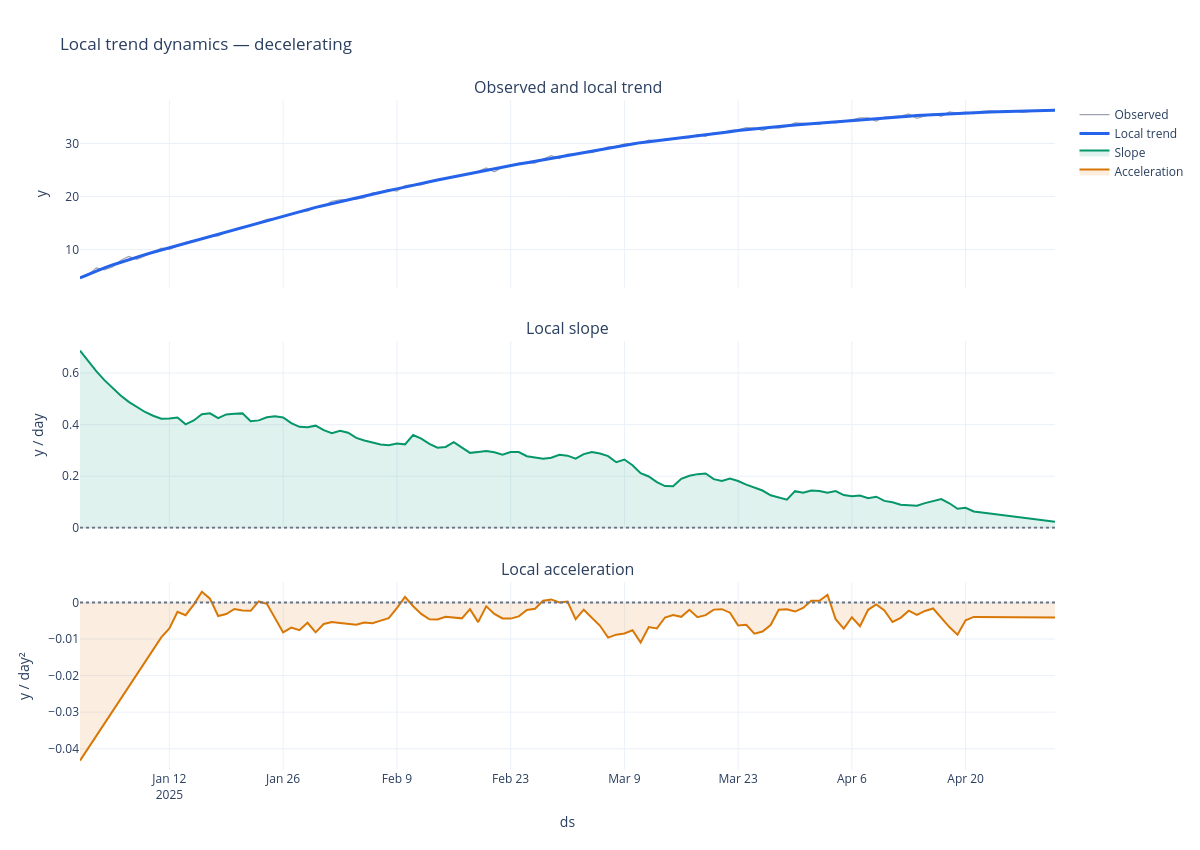

In [6]:
trend_dynamics(
    df, unique_id="decelerating", window_length=21,
    time_unit="day", fig_type="png",
)

## Turning point

At a local maximum, the slope changes from positive to negative. Negative acceleration describes the downward curvature around the turning point.

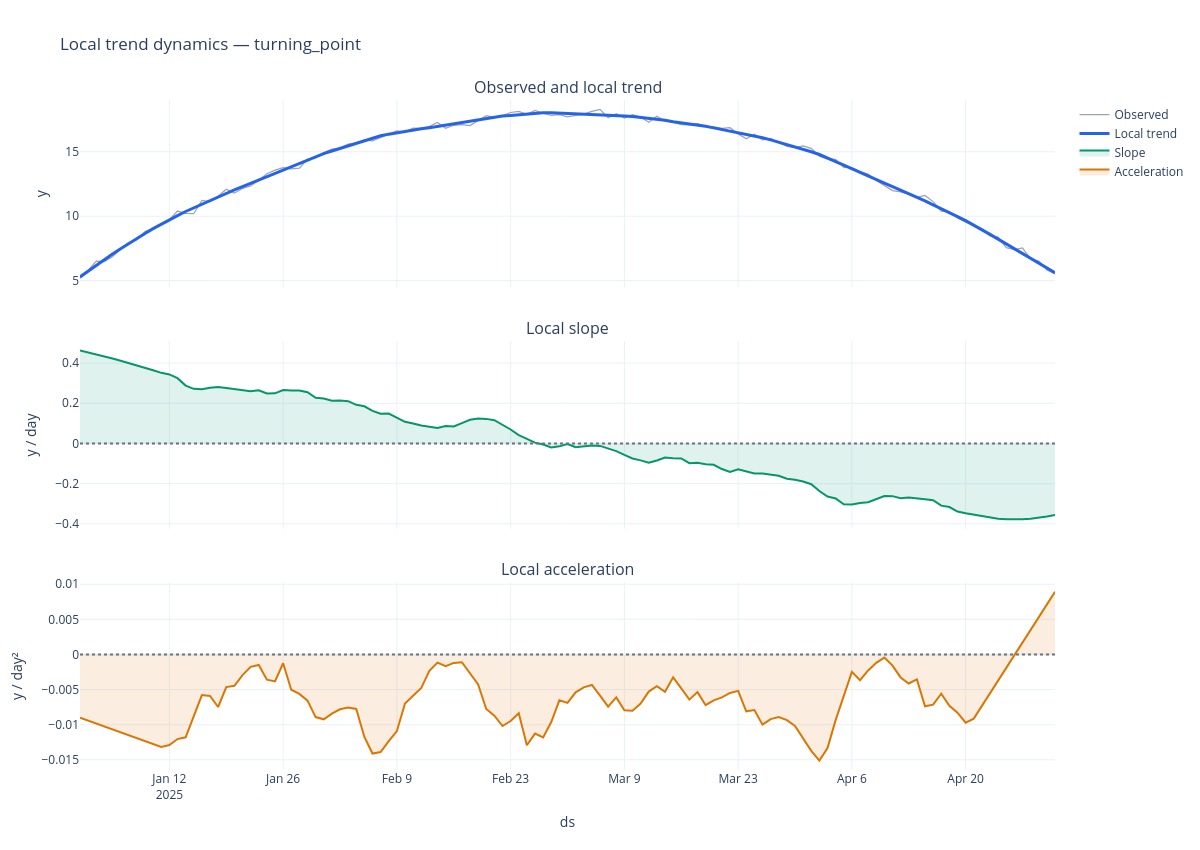

In [7]:
trend_dynamics(
    df, unique_id="turning_point", window_length=21,
    time_unit="day", fig_type="png",
)

## Structural break

A sudden change in slope is spread over the local window. The acceleration panel highlights the transition, but it should not be interpreted as a literal smooth physical acceleration.

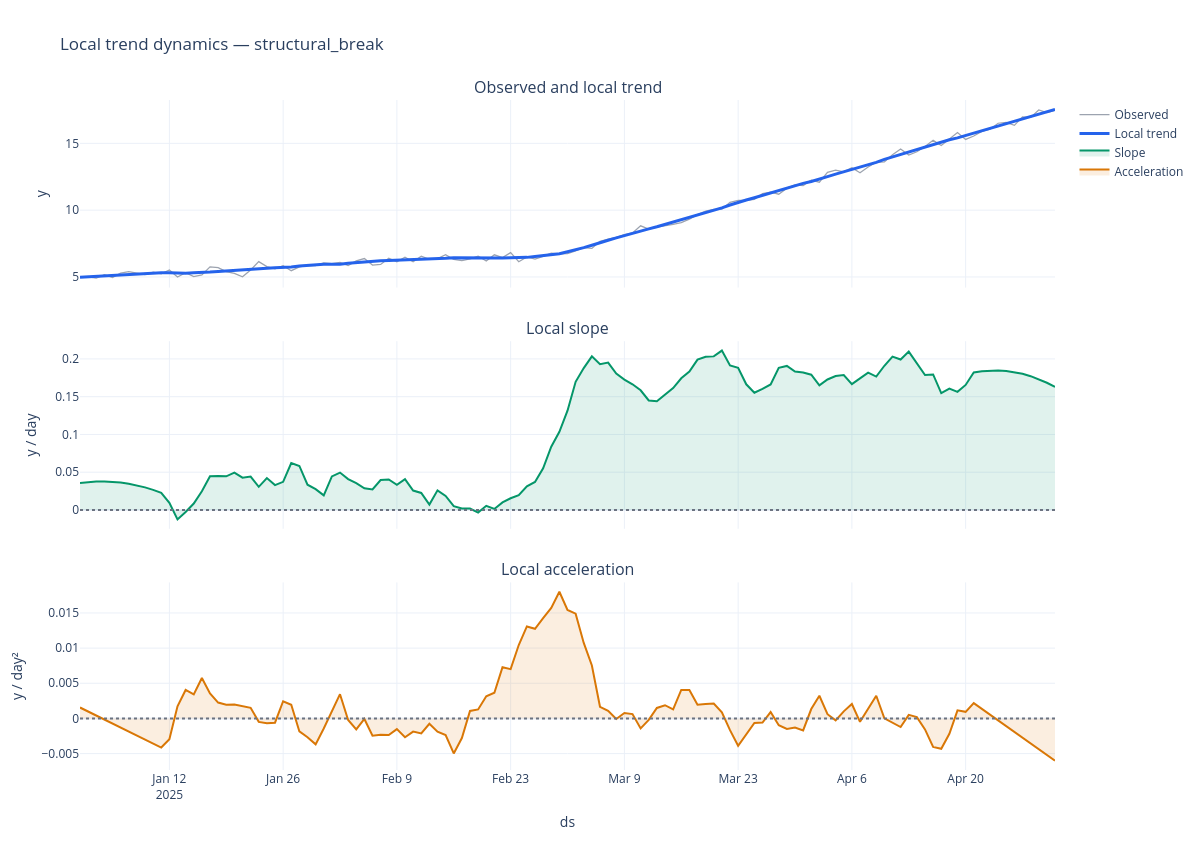

In [8]:
trend_dynamics(
    df, unique_id="structural_break", window_length=21,
    time_unit="day", fig_type="png",
)

## Trend with seasonality and noise

Derivatives amplify residual oscillations. A window spanning several seasonal cycles can reveal the underlying direction, but this diagnostic does not replace seasonal decomposition. For stronger or changing seasonality, analyze a deseasonalized component.

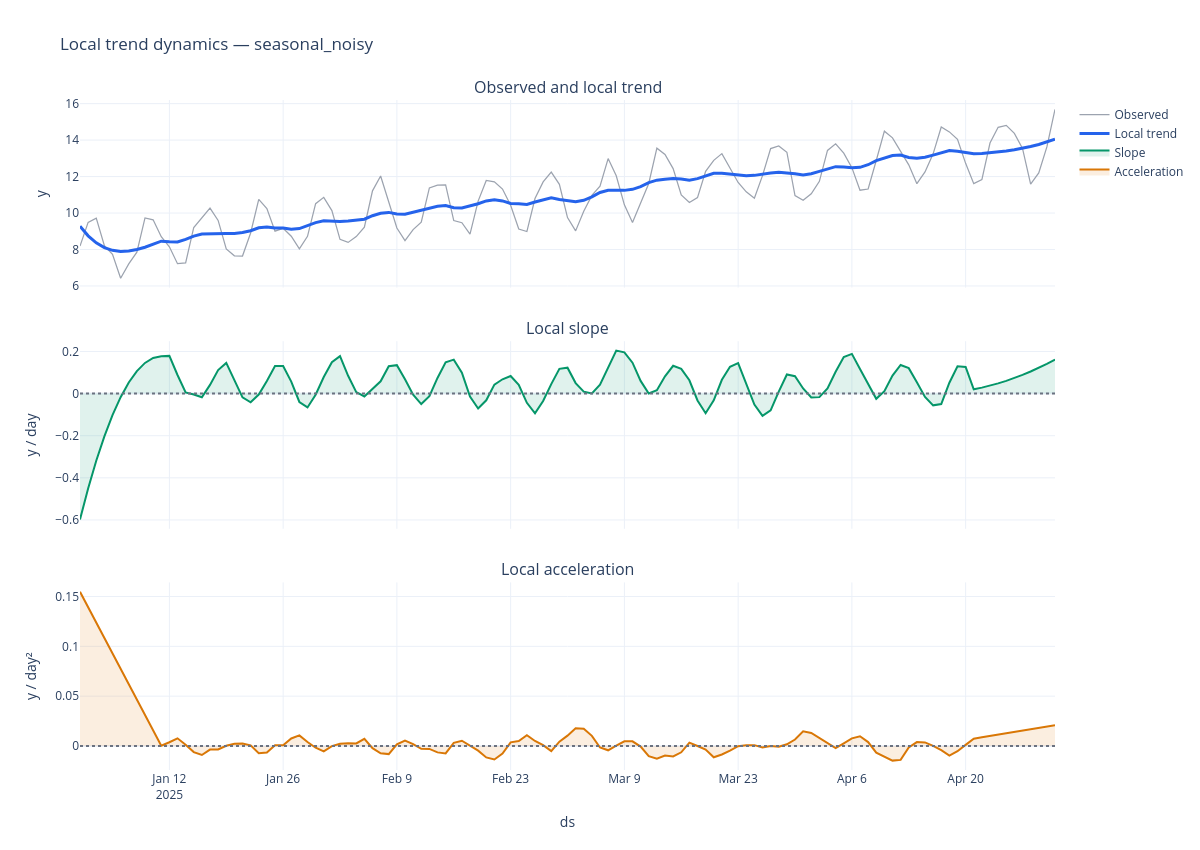

In [9]:
trend_dynamics(
    df, unique_id="seasonal_noisy", window_length=21,
    time_unit="day", fig_type="png",
)

## Window-length sensitivity

A short window responds quickly but leaves noisier derivatives. A long window is more stable but spreads local changes over a wider interval. There is no universally optimal window: it defines the temporal scale of the diagnostic.

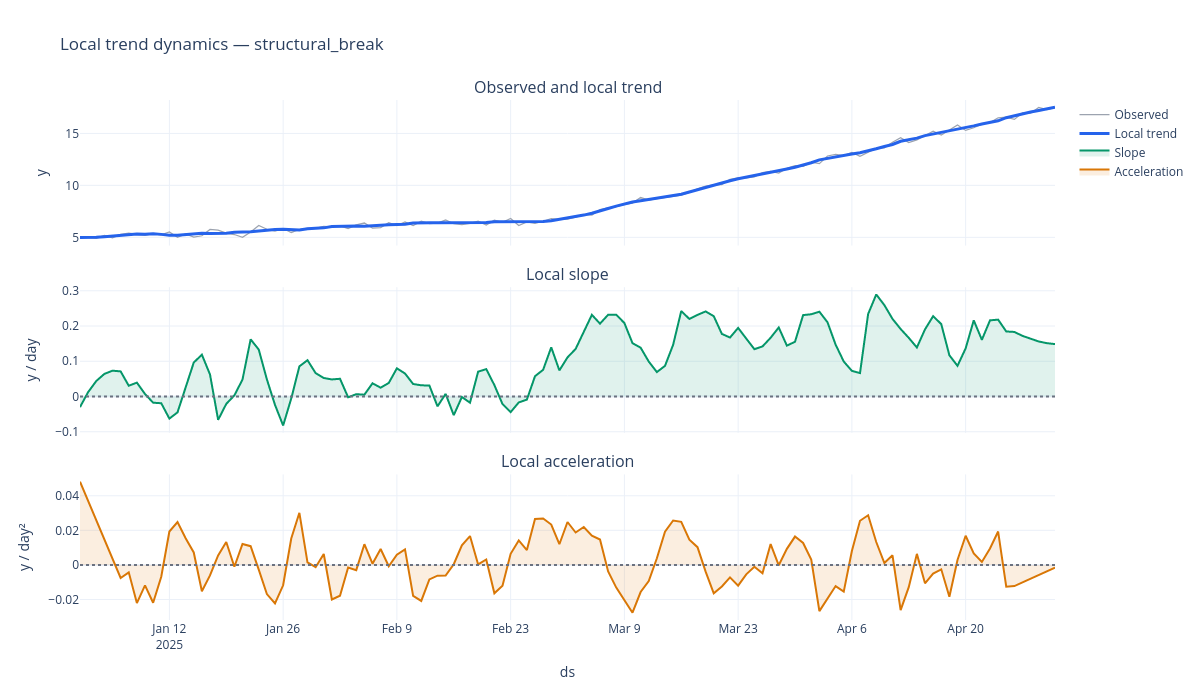

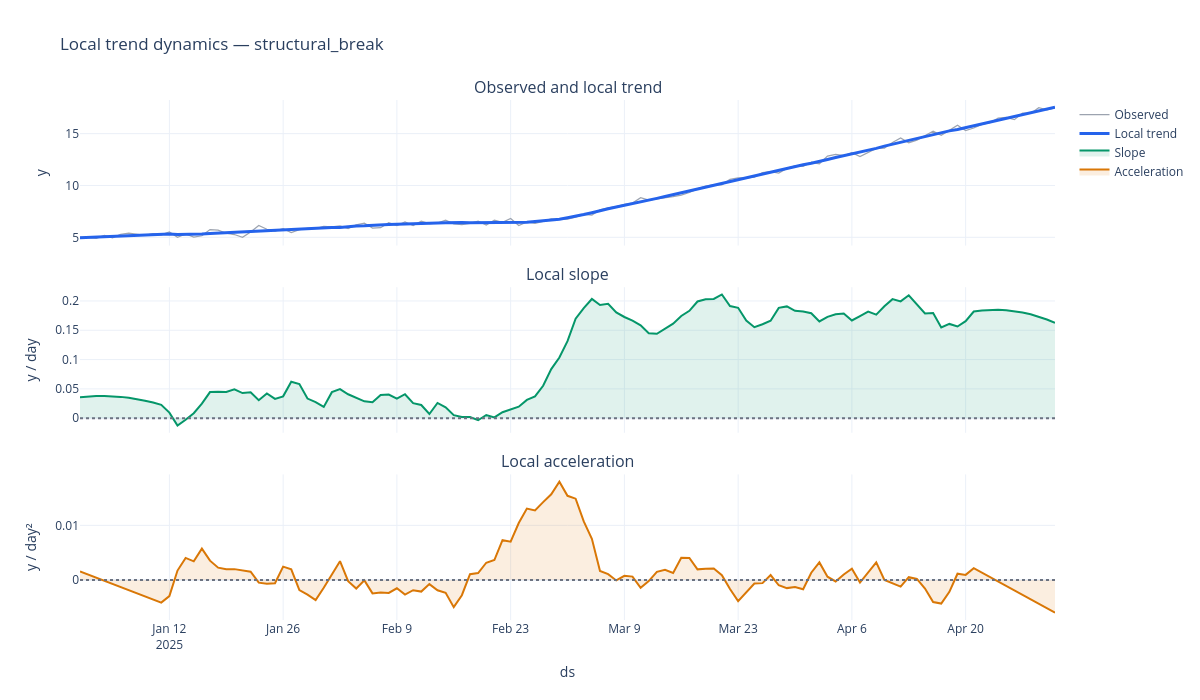

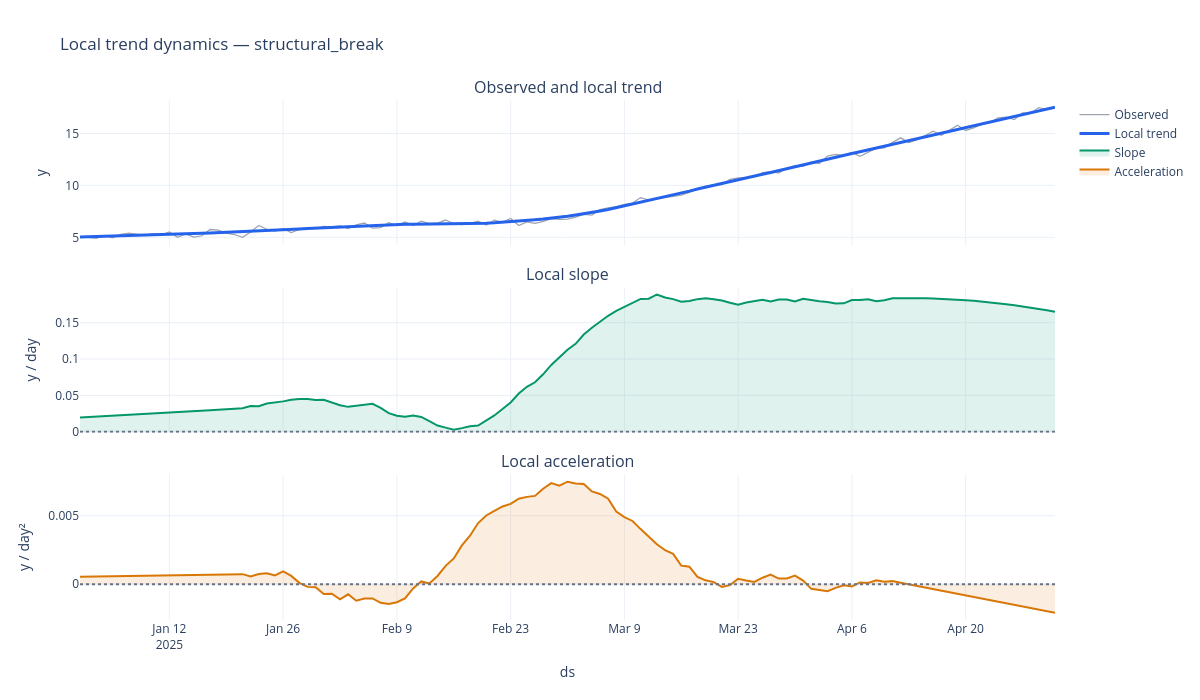

In [10]:
for window in (11, 21, 41):
    trend_dynamics(
        df, unique_id="structural_break", window_length=window,
        time_unit="day", fig_type="png", height=700,
    )

## Interpretation checklist

- Read slope and acceleration relative to zero, not as isolated magnitudes.
- Treat the first and last half-window with extra caution because they rely on boundary extrapolation.
- Choose the window according to the time scale of the change being investigated.
- Remove important seasonal structure before interpreting short-term derivatives.
- Use the plot as an exploratory diagnostic, not as evidence of causality or a formal change-point test.